---
title: "Self-study Lab 8: Logistic Regression with Multiple Features"
subtitle: "Machine Learning, Lecture 4: Logistic regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

In this self-study lab you will

- draw linear decision boundaries for two features, and explore them interactively;
- implement the cost function and its gradient, and train logistic regression with gradient descent;
- compare your result with scikit-learn, and understand when the two can differ;
- create a nonlinear (elliptic) decision boundary with polynomial features;
- train and evaluate a model on the breast-cancer data with scikit-learn.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element (Lab 7)."""
    return 1.0 / (1.0 + np.exp(-z))

## Decision boundaries with two features

With $n$ features the model is
$$
f_{\mathbf w,b}(\mathbf x) = g(\mathbf w\cdot\mathbf x + b) = \frac{1}{1 + e^{-(\mathbf w\cdot\mathbf x + b)}},
$$
and for the threshold $0.5$ the decision boundary is $\mathbf w\cdot\mathbf x + b = 0$ (Lab 7). With two features this is the straight line $w_1x_1 + w_2x_2 + b = 0$, which we can draw as $x_2 = -(w_1x_1 + b)/w_2$ (for $w_2 \ne 0$). We start with six examples:

In [2]:
X_toy = np.array([[0.5, 1.5], [1.0, 1.0], [1.5, 0.5], [3.0, 0.5], [2.0, 2.0], [1.0, 2.5]])
y_toy = np.array([0, 0, 0, 1, 1, 1])

def plot_data(X, y, ax=None):
    """Plot two-feature data: red crosses for y = 1, blue circles for y = 0."""
    ax = plt.gca() if ax is None else ax
    ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', c='r', s=60, label='$y = 1$')
    ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', facecolor='none', edgecolor='b', s=60, label='$y = 0$')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')

def plot_decision_regions(predict_fn, xlim, ylim, ax=None):
    """Colour the plane by the predicted class (blue: 0, red: 1) and draw the boundary in green."""
    ax = plt.gca() if ax is None else ax
    g1, g2 = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    y_hat = predict_fn(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
    ax.contourf(g1, g2, y_hat, levels=[-0.5, 0.5, 1.5], colors=['tab:blue', 'tab:red'], alpha=0.15)
    ax.contour(g1, g2, y_hat, levels=[0.5], colors='g', linewidths=2)

def predict(X, w, b, tau=0.5):
    """Class predictions (0 or 1) of a logistic regression model with threshold tau."""
    return (sigmoid(X @ w + b) >= tau).astype(int)

The lecture's example, $w_1 = w_2 = 1$ and $b = -3$, gives the boundary $x_1 + x_2 = 3$, with $\hat y = 1$ where $x_1 + x_2 \ge 3$:

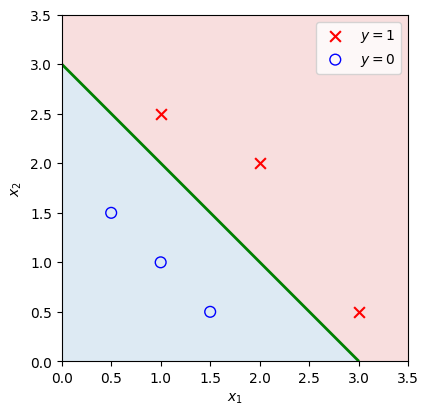

In [3]:
w_ex, b_ex = np.array([1.0, 1.0]), -3.0
plt.figure(figsize=(4.5, 4.5))
plot_decision_regions(lambda X: predict(X, w_ex, b_ex), (0, 3.5), (0, 3.5))
plot_data(X_toy, y_toy)
plt.legend()
plt.gca().set_aspect('equal')
plt.show()

::: {.callout-note title="Interactive version (Jupyter only)"}
The sliders need a running Python kernel, so the next cell is not executed in the HTML version. Run it in Jupyter, change $w_1$, $w_2$ and $b$, and find parameters that separate the two classes. Which parameters give the same line but a steeper sigmoid?
:::

In [ ]:
#| eval: false
from ipywidgets import interact, FloatSlider

@interact(w1=FloatSlider(value=1, min=-5, max=5, step=0.25, continuous_update=False),
          w2=FloatSlider(value=1, min=-5, max=5, step=0.25, continuous_update=False),
          b=FloatSlider(value=-3, min=-10, max=10, step=0.25, continuous_update=False))
def explore_boundary(w1, w2, b):
    w = np.array([w1, w2])
    plt.figure(figsize=(4.5, 4.5))
    plot_decision_regions(lambda X: predict(X, w, b), (0, 3.5), (0, 3.5))
    plot_data(X_toy, y_toy)
    errors = np.sum(predict(X_toy, w, b) != y_toy)
    plt.title(f'{errors} misclassified example(s)')
    plt.show()

With $n$ features the boundary $\mathbf w\cdot\mathbf x + b = 0$ is a (hyper)plane.

## Training with gradient descent

### Cost and gradient

The parameters are found by minimising the **logistic cost**
$$
J(\mathbf w, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log f_{\mathbf w,b}(\mathbf x^{(i)}) + \big(1 - y^{(i)}\big)\log\big(1 - f_{\mathbf w,b}(\mathbf x^{(i)})\big)\Big].
$$
Lab 10 explains where this cost comes from and why we do not use the squared error. Its gradient has the same form as for linear regression (Lab 3):
$$
\frac{\partial J}{\partial w_j} = \frac1m\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big)\,x_j^{(i)},
\qquad
\frac{\partial J}{\partial b} = \frac1m\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big),
$$
but with $f_{\mathbf w,b}(\mathbf x) = g(\mathbf w\cdot\mathbf x + b)$ instead of $\mathbf w\cdot\mathbf x + b$, so it is a different algorithm.

In [5]:
def compute_cost(X, y, w, b):
    """Logistic cost J(w, b), computed from z to avoid log(0) (see Lab 10)."""
    z = X @ w + b
    return np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z))

def compute_gradient(X, y, w, b):
    """Gradient of the logistic cost: dJ/dw (shape (n,)) and dJ/db."""
    err = sigmoid(X @ w + b) - y          # f - y, shape (m,)
    return X.T @ err / len(y), np.mean(err)

`np.logaddexp(0, t)` computes $\log(1 + e^{t})$; since $-\log g(z) = \log(1 + e^{-z})$ and $-\log\big(1 - g(z)\big) = \log(1 + e^{z})$, this is the same cost, but it never takes the logarithm of $0$ (Lab 10). As always, we check the gradient with central finite differences:

In [6]:
w_test, b_test = np.array([0.5, 0.25]), 0.1
eps = 1e-6
# the rows of eps * np.eye(2) are eps * e_1 and eps * e_2: change one weight at a time
fd_w = np.array([(compute_cost(X_toy, y_toy, w_test + e, b_test) - compute_cost(X_toy, y_toy, w_test - e, b_test)) / (2 * eps)
                 for e in eps * np.eye(2)])
fd_b = (compute_cost(X_toy, y_toy, w_test, b_test + eps) - compute_cost(X_toy, y_toy, w_test, b_test - eps)) / (2 * eps)
dJ_dw, dJ_db = compute_gradient(X_toy, y_toy, w_test, b_test)
print(f"compute_gradient:   dJ/dw = {dJ_dw}, dJ/db = {dJ_db:.6f}")
print(f"finite differences: dJ/dw = {fd_w}, dJ/db = {fd_b:.6f}")

compute_gradient:   dJ/dw = [0.185 0.182], dJ/db = 0.259020
finite differences: dJ/dw = [0.185 0.182], dJ/db = 0.259020


### Gradient descent

The function from the lecture, extended to record the cost:

In [7]:
def gradient_descent(X, y, alpha=0.5, n_iters=1000):
    """Batch gradient descent for logistic regression from w = 0, b = 0."""
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        J_history[t] = compute_cost(X, y, w, b)
        err = sigmoid(X @ w + b) - y          # (m,) errors
        w = w - alpha * X.T @ err / m         # simultaneous
        b = b - alpha * np.mean(err)          # update
    return w, b, J_history

We train it on the lecture's two-class data: $40$ examples per class around two different centres. The classes overlap, so no line separates them perfectly.

In [8]:
rng = np.random.default_rng(11)
X_blobs = np.vstack([rng.normal([-1.0, -0.6], 0.8, size=(40, 2)),     # class 0
                     rng.normal([1.0, 0.8], 0.8, size=(40, 2))])      # class 1
y_blobs = np.concatenate([np.zeros(40), np.ones(40)])

w_gd, b_gd, J_hist = gradient_descent(X_blobs, y_blobs, alpha=0.5, n_iters=1000)
sk_model = LogisticRegression(C=1e10).fit(X_blobs, y_blobs)    # C=1e10: no regularisation
print(f"gradient descent: w = {w_gd}, b = {b_gd:.3f}")
print(f"scikit-learn:     w = {sk_model.coef_[0]}, b = {sk_model.intercept_[0]:.3f}")
print(f"training accuracy: {np.mean(predict(X_blobs, w_gd, b_gd) == y_blobs):.3f}")

gradient descent: w = [3.598 2.259], b = -0.197
scikit-learn:     w = [3.607 2.262], b = -0.198
training accuracy: 0.950


As in the lecture, $1000$ iterations give $\mathbf w = (3.60, 2.26)$ and $b = -0.20$, the same as scikit-learn without regularisation; the small differences disappear with more iterations.

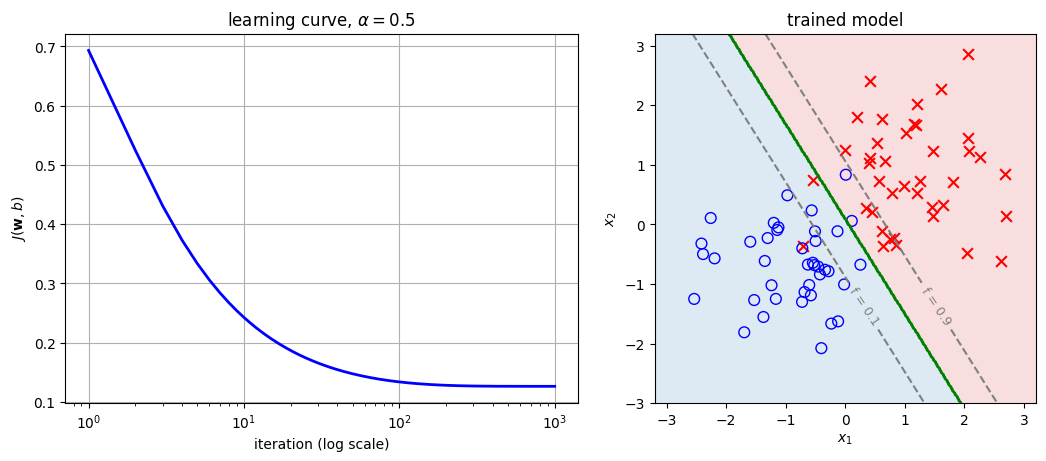

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax[0].semilogx(np.arange(1, len(J_hist) + 1), J_hist, 'b-', lw=2)
ax[0].set(xlabel='iteration (log scale)', ylabel='$J(\\mathbf{w}, b)$', title='learning curve, $\\alpha = 0.5$')
ax[0].grid(True)

plot_decision_regions(lambda X: predict(X, w_gd, b_gd), (-3.2, 3.2), (-3, 3.2), ax=ax[1])
g1, g2 = np.meshgrid(np.linspace(-3.2, 3.2, 200), np.linspace(-3, 3.2, 200))
cs = ax[1].contour(g1, g2, sigmoid(w_gd[0] * g1 + w_gd[1] * g2 + b_gd), levels=[0.1, 0.9],
                   colors='grey', linestyles='--')
ax[1].clabel(cs, fmt={0.1: 'f = 0.1', 0.9: 'f = 0.9'}, fontsize=9)
plot_data(X_blobs, y_blobs, ax=ax[1])
ax[1].set(title='trained model', aspect='equal')
plt.show()

$J$ decreases at every iteration and levels off. The boundary is the contour $f = 0.5$; between the dashed contours $f = 0.1$ and $f = 0.9$ the model is uncertain, which is exactly where the classes overlap.

### When gradient descent and scikit-learn disagree

Now train both on the six toy examples:

In [10]:
for n_iters in [1_000, 10_000]:
    w_t, b_t, _ = gradient_descent(X_toy, y_toy, alpha=0.5, n_iters=n_iters)
    print(f"gradient descent, {n_iters:6,d} iterations: w = {w_t}, b = {b_t:7.2f}, "
          f"boundary x2 = {-w_t[0] / w_t[1]:.2f} x1 + {-b_t / w_t[1]:.2f}")
sk_toy = LogisticRegression(C=1e10, max_iter=1000).fit(X_toy, y_toy)
w_sk, b_sk = sk_toy.coef_[0], sk_toy.intercept_[0]
print(f"scikit-learn:                   w = {w_sk}, b = {b_sk:7.2f}, "
      f"boundary x2 = {-w_sk[0] / w_sk[1]:.2f} x1 + {-b_sk / w_sk[1]:.2f}")

gradient descent,  1,000 iterations: w = [4.358 4.152], b =  -11.66, boundary x2 = -1.05 x1 + 2.81


gradient descent, 10,000 iterations: w = [7.43  7.229], b =  -20.15, boundary x2 = -1.03 x1 + 2.79
scikit-learn:                   w = [12.752 12.714], b =  -34.38, boundary x2 = -1.00 x1 + 2.70


The parameters are very different, and gradient descent keeps changing them, yet the decision boundaries are almost the same line. The reason is that these data are **perfectly separable**: once a line separates the classes, multiplying $\mathbf w$ and $b$ by a factor $> 1$ keeps the line but makes the sigmoid steeper, and this always lowers $J$. So $J$ has **no minimum**, the parameters grow without bound, and each method simply stops somewhere along the way. Lab 10 studies this in detail.

## Nonlinear decision boundaries

As in polynomial regression, new features make the boundary curved. With the features $x_1^2$ and $x_2^2$,
$$
f_{\mathbf w,b}(\mathbf x) = g\big(w_1x_1^2 + w_2x_2^2 + b\big),
$$
the boundary $w_1x_1^2 + w_2x_2^2 + b = 0$ is an ellipse. We generate data around the lecture's ellipse $x_1^2 + 2x_2^2 = 3$, with $y = 1$ mostly outside and $y = 0$ mostly inside, and some mixing near the boundary.

In [11]:
rng = np.random.default_rng(1)
X_ell = rng.uniform(-2.5, 2.5, size=(200, 2))
p_true = sigmoid(3 * (X_ell[:, 0]**2 + 2 * X_ell[:, 1]**2 - 3))     # probability of y = 1
y_ell = (rng.random(200) < p_true).astype(int)

ell_model = LogisticRegression(C=1e10, max_iter=1000).fit(X_ell**2, y_ell)   # features x1^2, x2^2
w_ell, b_ell = ell_model.coef_[0], ell_model.intercept_[0]
print(f"w = {w_ell}, b = {b_ell:.2f}")
print(f"scaled so that b = -3: w = {w_ell * (-3 / b_ell)}")

w = [2.723 5.36 ], b = -8.10
scaled so that b = -3: w = [1.008 1.985]


Scaled so that $b = -3$, the learned boundary is close to $x_1^2 + 2x_2^2 = 3$. The model is still linear in the parameters; only the features are new.

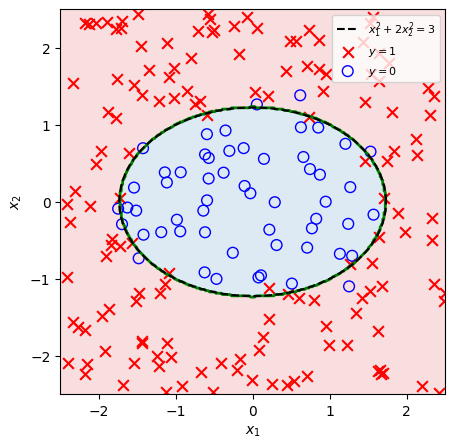

In [12]:
plt.figure(figsize=(5, 5))
plot_decision_regions(lambda X: ell_model.predict(X**2), (-2.5, 2.5), (-2.5, 2.5))
t = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.sqrt(3) * np.cos(t), np.sqrt(1.5) * np.sin(t), 'k--', label='$x_1^2 + 2x_2^2 = 3$')
plot_data(X_ell, y_ell)
plt.legend(loc='upper right', fontsize=8)
plt.gca().set_aspect('equal')
plt.show()

## Logistic regression with scikit-learn

We finish with the lecture's scikit-learn workflow on the breast-cancer data, using two features: the mean radius and the mean texture.

In [13]:
cancer = load_breast_cancer()
X = cancer.data[:, :2]                  # mean radius, mean texture
y = 1 - cancer.target                   # 1 = malignant (scikit-learn codes it as 0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
print(f"predicted classes: {model.predict(X_test[:3])}")
print(f"probabilities [P(y=0), P(y=1)]:\n{model.predict_proba(X_test[:3])}")
print(f"test accuracy: {model.score(X_test, y_test):.3f}")
print(f"baseline (always benign): {np.mean(y_test == 0):.3f}")

predicted classes: [1 0 0]
probabilities [P(y=0), P(y=1)]:
[[0.041 0.959]
 [0.89  0.11 ]
 [0.81  0.19 ]]
test accuracy: 0.923
baseline (always benign): 0.629


- `train_test_split(..., stratify=y)` keeps the fraction of malignant tumours equal in both sets; the test set is only used for evaluation.
- The **pipeline** scales the features with the training statistics and applies the same scaling to new data.
- `predict` uses $\tau = 0.5$; `predict_proba` returns one column per class; `score` returns the **accuracy**, the fraction of correct predictions.
- Always compare with a **baseline**: predicting "benign" for every tumour is already right $62.9\%$ of the time. With all 30 features (Challenge 4) the accuracy rises from $92.3\%$ to $98.6\%$.

For another threshold, compare the probabilities with $\tau$ yourself. We count both kinds of mistake on the test set:

In [14]:
p_malignant = model.predict_proba(X_test)[:, 1]
for tau in [0.3, 0.5, 0.7]:
    y_hat = (p_malignant >= tau).astype(int)
    missed = np.sum((y_test == 1) & (y_hat == 0))
    false_alarms = np.sum((y_test == 0) & (y_hat == 1))
    print(f"tau = {tau}: accuracy {np.mean(y_hat == y_test):.3f}, "
          f"missed tumours {missed:2d}, false alarms {false_alarms:2d}")

tau = 0.3: accuracy 0.916, missed tumours  5, false alarms  7
tau = 0.5: accuracy 0.923, missed tumours  8, false alarms  3
tau = 0.7: accuracy 0.895, missed tumours 14, false alarms  1


A lower threshold misses fewer malignant tumours at the cost of more false alarms, while the accuracy hardly changes: accuracy alone does not tell the whole story.

::: {.callout-note title="Regularisation and the shape of `coef_`"}
- `LogisticRegression` applies **regularisation** by default ($C = 1$, Lecture 5), which keeps the weights small. A very large $C$, such as `C=1e10`, switches it off. The lecture's `C=np.inf` does the same, but scikit-learn 1.8 then prints a misleading warning; older code uses `penalty=None`, deprecated since version 1.8.
- `coef_` has shape `(1, n)` for two classes and `intercept_` has shape `(1,)`. With $K > 2$ classes they have shapes `(K, n)` and `(K,)` (Lab 9).
:::

## Challenges

1. With $\mathbf w = (2, -1)$ and $b = 1$, is the point $\mathbf x = (0, 3)$ classified as $1$ or $0$? Work it out by hand and check with `predict`.
2. Train on the two-class data with $\alpha = 0.05$ and $\alpha = 5$. Plot the learning curves. What changes?
3. Use the features $x_1, x_2, x_1^2, x_2^2$ for the ellipse data. Does the boundary change much?
4. Repeat the scikit-learn workflow with all 30 features (`cancer.data`). What is the test accuracy?
5. *Flexible boundaries.* Load `make_moons(n_samples=160, noise=0.22, random_state=3)` from `sklearn.datasets` and fit `make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LogisticRegression(C=100, max_iter=5000))` for degree $1$ and $5$. Plot the decision regions and compare the training accuracies.

## Summary

- With two features the decision boundary $w_1x_1 + w_2x_2 + b = 0$ is a line; with $n$ features, a hyperplane.
- The gradient of the logistic cost has the same form as for linear regression; gradient descent changes only in `sigmoid(X @ w + b)`.
- On overlapping classes, gradient descent and unregularised scikit-learn agree. On perfectly separable data $J$ has no minimum, so the parameters differ although the boundaries agree.
- Polynomial features such as $x_1^2, x_2^2$ give nonlinear boundaries.
- scikit-learn: `make_pipeline(StandardScaler(), LogisticRegression())`, then `fit`, `predict`, `predict_proba` and `score`; compare with a baseline and choose the threshold for the application.

**Next:** more than two classes (Lab 9), and a closer look at the cost function (Lab 10).